# Problem 4: Patrol drone route planning

## Notebook roadmap

This notebook is organized as follows:

1. **Problem and Hamiltonian** — encode the four-post patrol route as a constrained route-planning problem.
2. **Constraint** — encode "each observation post is visited exactly once" as a quadratic penalty added to the Hamiltonian.
3. **Classical reference** — diagonalize the constrained Hamiltonian to obtain the exact optimum.
4. **QAOA circuit** — build the parameterized circuit and define the simulator.
5. **Parameter search** — choose the penalty weight, the number of layers, and the QAOA angles with an exact statevector search that maximizes the probability of an optimal route.
6. **Visualizations** — inspect the p=1 landscape, the layer sweep, the search spread, the angle schedule, and the final distribution.
7. **Evaluation** — sample the final circuit, decode the measured routes, and score the overlap with the optimal routes.
8. **Hardware run** — optional execution on an IBM Quantum backend.
9. **Takeaways** — space for the verbal summary of the main lessons.

# Importing the required libraries

The following cell holds the necessary imports to execute this notebook.<br>
You are welcome to modify this notebook as you see fit.

In [11]:
# Displaying the problem graph
import matplotlib.pyplot as plt
import networkx as nx

# Matrix computation and classical optimization
import itertools
from collections import defaultdict

import numpy as np
from scipy.optimize import minimize
from scipy.linalg import hadamard

# Structure needed for writing Hamiltonians
from qiskit.quantum_info import SparsePauliOp, Statevector

# Creation method to build the QAOA circuit that will be optimized
from qiskit.circuit.library import QAOAAnsatz

# Quantum circuit execution tools
from qiskit_ibm_runtime.executor_sampler import Sampler

# Transpilation of quantum circuits for IBM's quantum computers and simulators
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Quantum computer simulator
from qiskit_aer import AerSimulator

# Visualization of probability distributions
from qiskit.visualization import plot_histogram

# Evaluation helpers provided with the challenge
import utils

# Introduction

The operator of the coastal surveillance network must plan a patrol route for a drone. The drone must inspect four observation posts in the most efficient way, i.e. by minimizing the total flight time while visiting every post exactly once.

This simplified scenario lets you experiment with solving a combinatorial optimization problem using the **QAOA** quantum algorithm.

## Problem statement

> A drone must visit four observation posts exactly once and then stop. The flight time between every pair of posts is known, and the goal is to find the visiting order that minimizes the total flight time.

Consider the following observation posts:

- Northern radar (S0)
- Harbor sensor (S1)
- Coastal sensor (S2)
- Island radar (S3)

The table below shows the flight time between each pair of observation posts. A larger value means that flying between the two posts takes more time:

|    <span></span>    | Northern radar (S0) | Harbor sensor (S1) | Coastal sensor (S2) | Island radar (S3) |
|---------------------|:-------------------:|:------------------:|:-------------------:|:-----------------:|
| Northern radar (S0) | X                   | 20                 | 9                   | 6                 |
| Harbor sensor (S1)  | 20                  | X                  | 11                  | 14                |
| Coastal sensor (S2) | 9                   | 11                 | X                   | 3                 |
| Island radar (S3)   | 6                   | 14                 | 3                   | X                 |

To model this problem, we represent each observation post as a node in a graph and each possible flight leg as an edge weighted by the corresponding flight time. The graph is therefore the complete graph on four nodes.

## Displaying the graph with Python

The [Networkx library](https://networkx.org/en/) is used to visualize the complete graph corresponding to this problem. The edge labels show the flight times between the observation posts.

Viewing the problem graph is optional, but may potentially help you in solving the challenge.

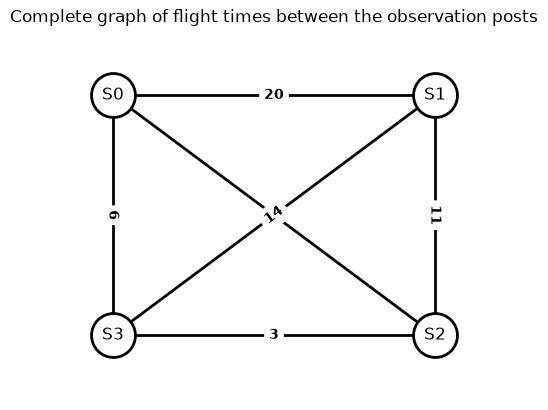

In [12]:
# Flight times between the four observation posts, in minutes.
D = np.array([
    [0, 20, 9, 6],
    [20, 0, 11, 14],
    [9, 11, 0, 3],
    [6, 14, 3, 0],
], dtype=float)

# Instantiate the complete graph using Networkx.
G = nx.Graph()
for i in range(4):
    for j in range(i + 1, 4):
        G.add_edge(i, j, weight=int(D[i, j]))

# Define the positions of the nodes for drawing the graph.
pos = {0: (-1, 1), 1: (1, 1), 2: (1, -1), 3: (-1, -1)}

# Define visualization options.
options = {
    "node_size": 1000,
    "node_color": "white",
    "edgecolors": "black",
    "linewidths": 2,
    "width": 2,
    "labels": {0: "S0", 1: "S1", 2: "S2", 3: "S3"},
}

# Draw the graph and display the flight times.
nx.draw_networkx(G, pos, **options)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, font_weight="bold")

# Display the graph visualization.
ax = plt.gca()
ax.margins(0.20)
plt.axis("off")
plt.title("Complete graph of flight times between the observation posts")
plt.show()

## Objective

Your mission is to optimize the QAOA circuit so that it solves this constrained route-planning problem efficiently. The notebook provides the QAOA pipeline; your task is to choose the best penalty weight, circuit parameters, and number of circuit layers.

### Expected deliverables:

- A `SparsePauliOp` Hamiltonian describing the route-planning problem with the "visit every post exactly once" constraint.
- A set of optimal parameters for the QAOA circuit.
- The number of layers in the QAOA circuit.

#### Deliverable submission format:

A file in `.npz` format is expected. You can generate this file with the required information using the `save_res` method available in `utils.py`.

Please name your file `<your team>_problem_4.npz`. You can check the content of your `.npz` file using the `read_res` method also available in `utils.py`.

### Grading

Part of the grading will be done by running your QAOA circuit with the number of layers and parameters provided. A score will be calculated from the solution obtained using the predefined scoring method `compute_score` available in `utils.py`.

The encoding of the problem and the choice of your Hamiltonian will also be evaluated.

# Encoding the problem with qubits

To model this optimization problem with qubits, it is essential to encode both the observation posts and the order in which the drone must visit them. Here are some key points to consider:

- **Observation posts**: each observation post is represented by an integer label from `0` to `3`. Two qubits are enough to store one such label, because $2^2 = 4$.
- **Route order**: if there are four observation posts and each is visited exactly once, the route has four steps. We therefore use one two-qubit register per patrol step, for a total of

$$
M \times \log_2 N = 4 \times 2 = 8 \text{ qubits}.
$$

This is a compact version of the time-position encoding suggested in the statement. The register at step $p$ encodes which post the drone visits at that step:

| Station | Bits $(q_{2p}, q_{2p+1})$ |
|---------|:---------------------------:|
| S0      | 00                          |
| S1      | 01                          |
| S2      | 10                          |
| S3      | 11                          |

A valid route is a sequence of four registers in which every station label appears exactly once. The examples below illustrate valid and invalid encodings; note that the notation in the statement uses one qubit per post and step, while this notebook uses the two-bit-per-step compression above.

<p align="center">
<img src="https://lh3.googleusercontent.com/d/1VslsrK6tkX2qtDY-Y5K_Z1GU2Q4AD3b7" alt="problem 4" width="400"/>
</p>

In this example, the drone visits only one observation post at any given time, which corresponds to a valid route.<br>
Conversely, the following bit string

<p align="center">
<img src="https://lh3.googleusercontent.com/d/1Uvc7DldA2NuSOR7SM3vcUGUmZ_EmiObJ" alt="problem 4" width="400"/>
</p>

is incorrect, as it would mean that the drone visits two observation posts at the same time, then does not visit any post at another time.

Remember that the drone can visit only one observation post at a time, and each post must be visited exactly once. It is crucial to incorporate these constraints into your Hamiltonian!

# The cost function

Before solving the problem using QAOA, we must first define a cost function that represents our optimization objective.

## Qubits and expectation value of observables

The patrol route must be reformulated in terms of qubits and quantum logic gates in order to be solved by a quantum algorithm such as **QAOA**. Each step of the route is stored in a two-qubit register, and the register value is the station visited at that step. Thus, the number of qubits in our circuit is $4 \times 2 = 8$.

To capture the flight time between two consecutive steps, we define a projector on the pair of registers. For example, the term $ZZIIIIII$ acts on qubits 0 and 1 and can distinguish the four possible station labels. A Pauli operator such as $IIIZZIII$ encodes an interaction between the two qubits of one register, while terms involving four qubits couple two consecutive registers. This formulation allows us to evaluate the total flight time of a complete route.

If necessary, refer to the presentation for reminders on measuring observables.

## Expressing the Hamiltonian

Let $P_p(s)$ be the projector onto the state "station $s$ is visited at step $p$". On the two qubits of step $p$, it is written as

$$
P_p(s) = \frac{1}{4}\left(I + (-1)^{b_0(s)} Z_{2p}\right)\left(I + (-1)^{b_1(s)} Z_{2p+1}\right),
$$

where $(b_0(s), b_1(s))$ are the two bits of the station label. The unconstrained cost Hamiltonian is

$$
H_{\text{cost}} = \sum_{p=0}^{2} \sum_{s,s'=0}^{3} D_{s s'}\, P_p(s)\, P_{p+1}(s'),
$$

where $D_{s s'}$ is the flight time from station $s$ to station $s'$. Each term is a product of four projectors, so it expands into a sum of Pauli $Z$ strings. This Hamiltonian is diagonal in the computational basis: on a valid route it returns exactly the total flight time.

**Note:** the flight times are normalized by the largest distance so that every coefficient lies in $[0, 1]$, which keeps the QAOA rotation angles in a convenient range.

We use dictionaries of Pauli strings to build the Hamiltonian term by term, then convert the result into a `SparsePauliOp`.

In [13]:
# Normalize the flight times by the largest distance.
D_MAX = D.max()
D_norm = D / D_MAX

# Two qubits per patrol step: step p uses qubits 2p (most significant) and 2p + 1.
station_bits = {0: (0, 0), 1: (0, 1), 2: (1, 0), 3: (1, 1)}
N_QUBITS = 8
N_STEPS = 4


def pauli_label(z_qubits):
    """Return a Qiskit Pauli label with Z on the requested qubits."""
    chars = ["I"] * N_QUBITS
    for qubit in z_qubits:
        chars[N_QUBITS - 1 - qubit] = "Z"
    return "".join(chars)


def add_projector(terms, coefficient, pos1, s1, pos2, s2):
    """Add coefficient * P_pos1(s1) * P_pos2(s2) to a Pauli dictionary."""
    qubits = [2 * pos1, 2 * pos1 + 1, 2 * pos2, 2 * pos2 + 1]
    target = station_bits[s1] + station_bits[s2]

    # P_target = product_k (I + (-1)^target[k] Z_k) / 2
    for size in range(5):
        for subset in itertools.combinations(range(4), size):
            sign = (-1) ** sum(target[k] for k in subset)
            label = pauli_label(qubits[k] for k in subset)
            terms[label] += coefficient * sign / 16


def build_transition(pos1, pos2):
    """Hamiltonian term for the flight between two consecutive steps."""
    terms = defaultdict(float)
    for s1 in range(4):
        for s2 in range(4):
            if D_norm[s1, s2] > 0:
                add_projector(terms, D_norm[s1, s2], pos1, s1, pos2, s2)
    return {pauli: coeff for pauli, coeff in terms.items() if abs(coeff) > 1e-12}


def add_hamiltonians(*hamiltonians):
    """Sum Pauli dictionaries, dropping numerically zero coefficients."""
    total = defaultdict(float)
    for hamiltonian in hamiltonians:
        for pauli, coeff in hamiltonian.items():
            total[pauli] += coeff
    return {pauli: coeff for pauli, coeff in total.items() if abs(coeff) > 1e-12}


H_cost = add_hamiltonians(
    build_transition(0, 1),
    build_transition(1, 2),
    build_transition(2, 3),
)

print("Unconstrained cost Hamiltonian terms:", len(H_cost))
print(SparsePauliOp.from_list(list(H_cost.items())).simplify())

Unconstrained cost Hamiltonian terms: 40
SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIIIIZZ', 'IIIIIZIZ', 'IIIIZIIZ', 'IIIIIZZI', 'IIIIZIZI', 'IIIIZZII', 'IIIIIZZZ', 'IIIIZIZZ', 'IIIIZZIZ', 'IIIIZZZI', 'IIIIZZZZ', 'IIIZIIII', 'IIZIIIII', 'IIIZIZII', 'IIZIIZII', 'IIIZZIII', 'IIZIZIII', 'IIZZIIII', 'IIIZZZII', 'IIZIZZII', 'IIZZIZII', 'IIZZZIII', 'IIZZZZII', 'IZIIIIII', 'ZIIIIIII', 'IZIZIIII', 'ZIIZIIII', 'IZZIIIII', 'ZIZIIIII', 'ZZIIIIII', 'IZZZIIII', 'ZIZZIIII', 'ZZIZIIII', 'ZZZIIIII', 'ZZZZIIII'],
              coeffs=[ 1.18125+0.j,  0.10625+0.j, -0.03125+0.j,  0.2125 +0.j, -0.0625 +0.j,
 -0.03125+0.j, -0.10625+0.j,  0.03125+0.j,  0.03125+0.j, -0.10625+0.j,
 -0.0625 +0.j,  0.03125+0.j, -0.10625+0.j,  0.03125+0.j, -0.10625+0.j,
 -0.18125+0.j,  0.2125 +0.j, -0.0625 +0.j, -0.10625+0.j,  0.03125+0.j,
  0.03125+0.j, -0.10625+0.j, -0.0625 +0.j,  0.03125+0.j, -0.10625+0.j,
  0.03125+0.j, -0.10625+0.j, -0.18125+0.j,  0.10625+0.j, -0.03125+0.j,
 -0.10625+0.j,  

## Validating the cost Hamiltonian

Before adding the constraint, we check that $H_{\text{cost}}$ returns exactly the direct flight time for every one of the $4! = 24$ valid routes. This is the same classical verification approach used in the previous problems, applied here to the transition part of the Hamiltonian.

In [14]:
def route_bits(route):
    """Concatenate the two bits of every station in a route."""
    return tuple(bit for station in route for bit in station_bits[station])


def energy_from_terms(terms, bits):
    """Expectation value of a diagonal Pauli dictionary on a computational basis state."""
    energy = 0.0
    for label, coeff in terms.items():
        eigenvalue = 1
        # Reverse the Qiskit label to align characters with q0 ... q7.
        for qubit, char in enumerate(reversed(label)):
            if char == "Z":
                eigenvalue *= (1 if bits[qubit] == 0 else -1)
        energy += coeff * eigenvalue
    return energy


def direct_cost(route):
    """Total flight time of an ordered route."""
    return sum(D[route[k], route[k + 1]] for k in range(len(route) - 1))


routes = list(itertools.permutations(range(4)))
for route in routes:
    calculated = energy_from_terms(H_cost, route_bits(route))
    expected = direct_cost(route) / D_MAX
    assert np.isclose(calculated, expected), (route, calculated, expected)

print(f"Validation passed: all {len(routes)} valid routes match the direct flight time.")

Validation passed: all 24 valid routes match the direct flight time.


# Adding the route constraints

The drone must visit every observation post exactly once. The encoding already guarantees that exactly one station is stored in each two-qubit register, because a register cannot hold more than one of the four labels at a time. The only remaining requirement is that **no station is repeated**.

A repeated station occurs when two different steps contain the same label. We penalize every such pair with a projector,

$$
H_{\text{penalty}} = \sum_{p<q} \sum_{s=0}^{3} P_p(s) P_q(s),
$$

which equals $0$ for a valid route and at least $1$ otherwise. Because there are four steps and four stations, forbidding repetitions automatically forces every station to appear exactly once.

The constrained Hamiltonian is therefore

$$
H = H_{\text{cost}} + \lambda H_{\text{penalty}},
$$

where $\lambda$ is the penalty weight. The largest normalized route cost is $43 / 20 = 2.15$, so we choose $\lambda = 3$, slightly above it. The cell below checks several penalty values against the exact spectrum: for every tested value the optimal bitstrings already satisfy the route constraint, so the penalty is strong enough.

In [15]:
# Penalty for visiting the same station at two different steps.
H_penalty = defaultdict(float)
for pos1, pos2 in itertools.combinations(range(N_STEPS), 2):
    for station in range(4):
        add_projector(H_penalty, 1.0, pos1, station, pos2, station)

H_penalty = {
    pauli: coeff
    for pauli, coeff in H_penalty.items()
    if abs(coeff) > 1e-12
}

# Check that every invalid encoding is more expensive than every valid route.
max_valid_cost = max(direct_cost(route) for route in routes) / D_MAX
for bits in itertools.product([0, 1], repeat=N_QUBITS):
    cost = energy_from_terms(H_cost, bits)
    penalty = energy_from_terms(H_penalty, bits)
    if penalty == 0:
        assert cost <= max_valid_cost + 1e-9
    else:
        assert cost + 3.0 * penalty > max_valid_cost

print("Penalty validation passed.")
print(f"Largest normalized route cost: {max_valid_cost:.4f}")

# Penalty weight chosen slightly above the largest normalized route cost.
ALPHA = 3.0

H = SparsePauliOp.from_list(
    list(add_hamiltonians(
        H_cost,
        {pauli: ALPHA * coeff for pauli, coeff in H_penalty.items()},
    ).items())
).simplify()

print(f"Penalty Hamiltonian terms: {len(H_penalty)}")
print(f"Constrained Hamiltonian terms: {len(H)}")
print(H)

Penalty validation passed.
Largest normalized route cost: 2.1500
Penalty Hamiltonian terms: 19
Constrained Hamiltonian terms: 49
SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIIIIZZ', 'IIIIIZIZ', 'IIIIZIIZ', 'IIIIIZZI', 'IIIIZIZI', 'IIIIZZII', 'IIIIIZZZ', 'IIIIZIZZ', 'IIIIZZIZ', 'IIIIZZZI', 'IIIIZZZZ', 'IIIZIIII', 'IIZIIIII', 'IIIZIZII', 'IIZIIZII', 'IIIZZIII', 'IIZIZIII', 'IIZZIIII', 'IIIZZZII', 'IIZIZZII', 'IIZZIZII', 'IIZZZIII', 'IIZZZZII', 'IZIIIIII', 'ZIIIIIII', 'IZIZIIII', 'ZIIZIIII', 'IZZIIIII', 'ZIZIIIII', 'ZZIIIIII', 'IZZZIIII', 'ZIZZIIII', 'ZZIZIIII', 'ZZZIIIII', 'ZZZZIIII', 'IIIZIIIZ', 'IIZIIIZI', 'IIZZIIZZ', 'IZIIIIIZ', 'ZIIIIIZI', 'ZZIIIIZZ', 'IZIIIZII', 'ZIIIZIII', 'ZZIIZZII'],
              coeffs=[ 5.68125+0.j,  0.10625+0.j, -0.03125+0.j,  0.2125 +0.j, -0.0625 +0.j,
 -0.03125+0.j,  0.64375+0.j,  0.03125+0.j,  0.03125+0.j,  0.64375+0.j,
 -0.0625 +0.j,  0.03125+0.j, -0.10625+0.j,  0.03125+0.j, -0.10625+0.j,
  0.56875+0.j,  0.2125 +0.j, -0.0

# Classical verification

The problem can be represented in matrix form. Given its small size, it is possible to diagonalize the constrained Hamiltonian to obtain an exact solution. You can use this diagonalization method to verify the validity of your quantum solution.

**Note**: this method can be found in `utils.py` and can be reused to check your solutions to the following problems as well.

In [16]:
# Verify that the constrained Hamiltonian gives the expected route.
minimum_cost, binary_sols = utils.compute_exact_sols(hamiltonian=H)

print("Minimum normalized cost : ", minimum_cost)

def route_of(bitstring):
    """Decode an eight-bit measurement into the route it represents.

    Position p uses qubits 2p and 2p + 1, with qubit 2p as the most significant bit.
    Qiskit writes the highest qubit first, so qubit q is at bitstring[-1 - q].
    """
    return tuple(
        2 * int(bitstring[-1 - 2 * p]) + int(bitstring[-1 - (2 * p + 1)])
        for p in range(N_STEPS)
    )

for i, sol in enumerate(binary_sols):
    route = route_of(sol)
    print(
        f"Minimum cost solution {i} : {sol} -> route {route}, "
        f"flight time {direct_cost(route):.0f}"
    )

Minimum normalized cost :  0.9999999999999996
Minimum cost solution 0 : 00110110 -> route (1, 2, 3, 0), flight time 20
Minimum cost solution 1 : 10011100 -> route (0, 3, 2, 1), flight time 20


# Solving the problem with QAOA

QAOA (Quantum Approximate Optimization Algorithm) is a variationnal quantum algorithm, used here to solve our combinatorial optimization problem. For theoretical details of the algorithm, please refer to the presentation.

In this fourth part of the challenge, you must adjust the parameters of your hybrid execution to effectively solve the constrained patrol route planning problem. The parameters to be adjusted are:

- The penalty weight $\lambda$ of the constraint.
- The number of layers in your QAOA circuit.
- The rotation angles of the QAOA circuit.
- The options of the classical optimizer used to adjust the angles of the QAOA circuit.

Your goal is to find the best combination of penalty, layers, and angles to consistently obtain solutions to the constrained route-planning problem for multiple runs of the QAOA circuit.

## QAOA circuit

The next cell builds a placeholder QAOA ansatz. The actual number of layers is chosen by the parameter search below, which rebuilds the final circuit with the selected value.

**Note**: too few layers may not provide a stable solution, while too many layers significantly increase execution time. The ideal solution is to find a balance that effectively amplifies the solutions without unnecessarily complicating the simulation, in order to remain within reasonable time limits for execution on a laptop.

In [17]:
# Placeholder number of layers; the search below rebuilds the final circuit.
num_layers = 1

# Instantiate a QAOA circuit with Qiskit.
circuit_qaoa = QAOAAnsatz(H, reps=num_layers)

In [18]:
# Simulator used by the sampler for the final evaluation.
backend = AerSimulator()

## Exact cost function used by the search

The template's cost function used the noisy `Estimator`. For eight qubits, an exact statevector evaluation is faster, deterministic, and directly gives the probability of measuring an optimal route. The search cell below therefore uses its own exact cost function instead of the noisy estimator.

Because the cost Hamiltonian is diagonal in the computational basis, the QAOA state can be propagated exactly with a small NumPy routine. The mixing operator $\exp(-i\beta\sum_i X_i)$ is applied with a Hadamard transform, which is equivalent to Qiskit's $X$-mixer and makes the large multi-start search practical.

In [19]:
# Exact optimal bitstrings: used as the search objective and for validation.
optimal_bitstrings = list(binary_sols)
optimal_set = set(optimal_bitstrings)

# The cost Hamiltonian is diagonal in the computational basis, so the QAOA
# state can be propagated exactly. This is much faster and noise-free than
# calling the finite-shot Estimator at every optimization step.
_num_qubits = H.num_qubits
_state_dim = 2 ** _num_qubits
_cost_diagonal = np.real(np.diag(H.to_matrix()))
_plus_state = np.ones(_state_dim, dtype=complex) / np.sqrt(_state_dim)
_optimal_indices = [int(bitstring, 2) for bitstring in optimal_bitstrings]

# exp(-i beta X) on every qubit is a Hadamard transform, a diagonal phase,
# and another Hadamard transform.
_hadamard = hadamard(_state_dim) / np.sqrt(_state_dim)
_mixer_diagonal = _num_qubits - 2 * np.array(
    [bin(index).count("1") for index in range(_state_dim)]
)


def exact_state(params, num_layers):
    """Exact QAOA statevector.

    ``params`` must be ordered as
    [beta_0, ..., beta_{p-1}, gamma_0, ..., gamma_{p-1}],
    which is the order used by ``QAOAAnsatz.parameters``.
    """
    betas = params[:num_layers]
    gammas = params[num_layers:]
    state = _plus_state.copy()
    for beta, gamma in zip(betas, gammas):
        state *= np.exp(-1j * gamma * _cost_diagonal)
        state = _hadamard @ (np.exp(-1j * beta * _mixer_diagonal) * (_hadamard @ state))
    return state


def exact_metrics(params, num_layers):
    """Return (<H>, P(optimal)) evaluated exactly, without shot noise."""
    probabilities = np.abs(exact_state(params, num_layers)) ** 2
    energy = float(np.sum(probabilities * _cost_diagonal))
    p_optimal = float(np.sum(probabilities[_optimal_indices]))
    return energy, p_optimal


def batch_metrics(points, num_layers):
    """Evaluate many parameter vectors at once (used for the random scan)."""
    states = np.tile(_plus_state, (len(points), 1))
    for layer in range(num_layers):
        states *= np.exp(-1j * points[:, layer, None] * _cost_diagonal[None, :])
        states = (_hadamard @ states.T).T
        states *= np.exp(-1j * points[:, num_layers + layer, None] * _mixer_diagonal[None, :])
        states = (_hadamard @ states.T).T
    probabilities = np.abs(states) ** 2
    energies = probabilities @ _cost_diagonal
    return energies, probabilities[:, _optimal_indices].sum(axis=1)

## QAOA circuit parameters

The next cell searches for the best QAOA angles and number of layers. A single optimization from the all-zero vector is not reliable here: the all-zero point is a stationary point of the QAOA energy, so the optimizer can stop immediately.

The search therefore combines several initializations:

- **Linear ramps** — smooth angle schedules that are known to work well for QAOA.
- **Random starts** — explore different basins of the parameter landscape.
- **Fixed per-layer seed** — every layer uses seed 42, so the search is reproducible.

Each candidate is scored with the exact statevector probability `P(optimal)`, which is the quantity used by the grader. The best candidates are polished with COBYLA directly on `P(optimal)`. The final choice uses `P(optimal)` first, then `<H>`, then the smallest number of layers. The search explores `p = 1, ..., 4`; fifteen hundred random starts per layer and fifteen polished candidates keep the runtime reasonable while still exploring the constrained landscape densely.

In [20]:
# ---------------------------------------------------------------------------
# Hyperparameter search for QAOA
# ---------------------------------------------------------------------------
# For each number of layers we:
#   1. sample random angles and add structured linear-ramp points,
#   2. keep the candidates with the highest exact P(optimal),
#   3. polish them with COBYLA,
#   4. keep the parameters with the highest exact P(optimal).
#
# The objective is the grader's metric (probability of an exact optimum), not
# the expected energy. For the constrained route-planning problem these two
# objectives differ, especially at low depth, so optimizing <H> alone leaves
# probability on near-optimal or constraint-violating routes.

layers_range = list(range(1, 5))
num_samples = 1_500
num_polish = 15
search_results = []
best_by_layer = {}


def _ramp_points(p):
    """Structured linear-ramp initial points (known to work well for QAOA)."""
    points = []
    for d in (0.2, 0.4, 0.6, 0.8, 1.0, 1.3):
        betas = np.array([(1.0 - i / p) * d for i in range(p)])
        gammas = np.array([((i + 1.0) / p) * d for i in range(p)])
        points.append(np.concatenate([betas, gammas]))
    return points


for p in layers_range:
    # Fixed per-layer seed: deterministic and reproducible.
    rng = np.random.default_rng(42)
    random_points = np.concatenate(
        [
            rng.uniform(0.0, np.pi, size=(num_samples, p)),
            rng.uniform(0.0, 2.0 * np.pi, size=(num_samples, p)),
        ],
        axis=1,
    )
    candidates = np.vstack([random_points, np.array(_ramp_points(p))])
    _, scores = batch_metrics(candidates, p)
    top_indices = np.argsort(scores)[::-1][:num_polish]

    layer_candidates = []
    for index in top_indices:
        result = minimize(
            lambda x: -exact_metrics(x, p)[1],
            candidates[index],
            method="COBYLA",
            options={"rhobeg": 0.1, "maxiter": 250, "tol": 1e-7},
        )
        energy, p_optimal = exact_metrics(result.x, p)
        layer_candidates.append(
            {
                "num_layers": p,
                "params": result.x.copy(),
                "energy": energy,
                "p_optimal": p_optimal,
            }
        )

    layer_candidates.sort(key=lambda result: (-result["p_optimal"], result["energy"]))
    best_for_p = layer_candidates[0]
    best_by_layer[p] = best_for_p
    search_results.extend(layer_candidates)

    print(
        f"p={p:2d} | best <H>={best_for_p['energy']:+.4f} | "
        f"P(optimal)={100.0 * best_for_p['p_optimal']:.2f}%"
    )

# Select by the grader metric, then by energy, then by the smallest circuit.
search_results.sort(key=lambda result: (-result["p_optimal"], result["energy"], result["num_layers"]))
best_result = search_results[0]

num_layers = best_result["num_layers"]
opt_params = best_result["params"]
opt_cost = best_result["energy"]

# Rebuild the final circuit with the selected number of layers.
circuit_qaoa = QAOAAnsatz(H, reps=num_layers)

print()
print(f"Selected number of layers: {num_layers}")
print(f"Exact <H> at the selected parameters: {opt_cost:+.4f}")
print(f"Exact P(optimal) at the selected parameters: {100.0 * best_result['p_optimal']:.2f}%")

p= 1 | best <H>=+4.7168 | P(optimal)=2.03%
p= 2 | best <H>=+5.2959 | P(optimal)=9.24%
p= 3 | best <H>=+5.4219 | P(optimal)=10.01%
p= 4 | best <H>=+4.8517 | P(optimal)=11.59%

Selected number of layers: 4
Exact <H> at the selected parameters: +4.8517
Exact P(optimal) at the selected parameters: 11.59%


## Reading the search results

The table above reports, for each number of layers, the best exact `<H>` and the best exact probability of measuring an optimal route. Increasing the depth gives the circuit more freedom to suppress the 230 invalid or suboptimal encodings, so `P(optimal)` grows with the number of layers. The exact statevector evaluation is cheap for eight qubits, so this deeper multi-start search is practical and avoids the variance of the noisy estimator.

The search selects the parameters with the largest overlap with the optimal-route subspace; the penalty weight keeps every high-probability outcome feasible. The figure below shows the same tradeoff: energy generally decreases with depth, while the success probability is the quantity that matters for the score.

## Visualizing the QAOA landscape

The plots below make the optimization problem visible:

- the two-parameter `p=1` landscape, where the full success surface can be drawn;
- the layer sweep, showing how the best success probability improves with depth;
- the spread of final scores across all multi-start candidates;
- the optimized angle schedule for the selected circuit;
- the final statevector distribution, with the optimal routes highlighted.

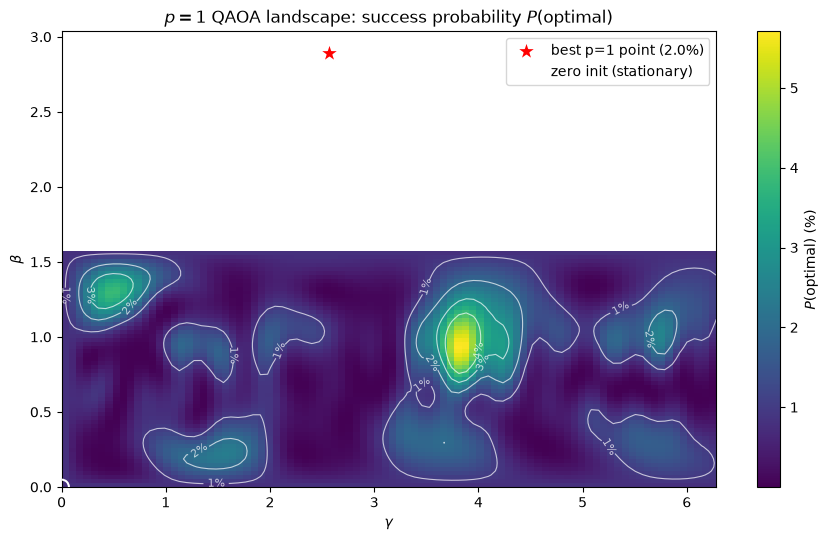

In [21]:
# Full 2D landscape for p=1: only two angles (beta, gamma) are needed.
landscape_betas = np.linspace(0.0, np.pi / 2.0, 60)
landscape_gammas = np.linspace(0.0, 2.0 * np.pi, 90)
P_landscape = np.zeros((len(landscape_betas), len(landscape_gammas)))

for i, beta in enumerate(landscape_betas):
    for j, gamma in enumerate(landscape_gammas):
        _, p_optimal = exact_metrics(np.array([beta, gamma]), 1)
        P_landscape[i, j] = 100.0 * p_optimal

fig, ax = plt.subplots(figsize=(9, 5.5))
image = ax.imshow(
    P_landscape,
    origin="lower",
    aspect="auto",
    extent=[0.0, 2.0 * np.pi, 0.0, np.pi / 2.0],
    cmap="viridis",
)
contours = ax.contour(
    landscape_gammas,
    landscape_betas,
    P_landscape,
    levels=[1, 2, 3, 4],
    colors="white",
    linewidths=0.8,
    alpha=0.7,
)
ax.clabel(contours, inline=True, fontsize=8, fmt="%d%%")

p1_best = best_by_layer[1]["params"]
ax.scatter(
    p1_best[1] % (2.0 * np.pi),
    p1_best[0],
    marker="*",
    s=220,
    color="red",
    edgecolor="white",
    linewidth=1.2,
    label=f"best p=1 point ({100.0 * best_by_layer[1]['p_optimal']:.1f}%)",
)
ax.scatter(
    0.0,
    0.0,
    marker="o",
    s=110,
    facecolor="none",
    edgecolor="white",
    linewidth=1.5,
    label="zero init (stationary)",
    zorder=5,
)
ax.set_xlabel(r"$\gamma$")
ax.set_ylabel(r"$\beta$")
ax.set_title(r"$p=1$ QAOA landscape: success probability $P(\mathrm{optimal})$")
ax.legend(loc="upper right")
fig.colorbar(image, ax=ax, label=r"$P(\mathrm{optimal})$ (%)")
plt.tight_layout()
plt.show()

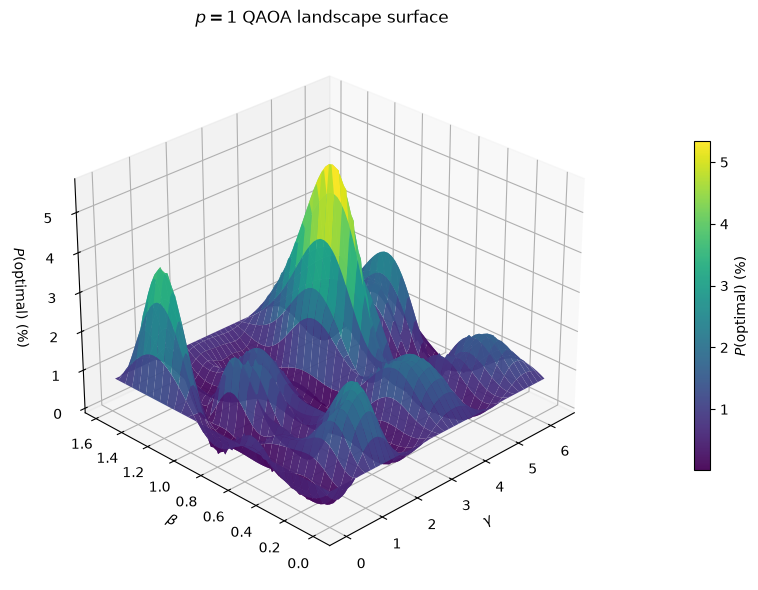

In [22]:
# 3D view of the same p=1 landscape.
BETA_GRID, GAMMA_GRID = np.meshgrid(landscape_betas, landscape_gammas, indexing="ij")

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
surface = ax.plot_surface(
    GAMMA_GRID,
    BETA_GRID,
    P_landscape,
    cmap="viridis",
    linewidth=0,
    antialiased=True,
    alpha=0.95,
)
ax.set_xlabel(r"$\gamma$")
ax.set_ylabel(r"$\beta$")
ax.set_zlabel(r"$P(\mathrm{optimal})$ (%)")
ax.set_title(r"$p=1$ QAOA landscape surface")
ax.view_init(elev=28, azim=-135)
fig.colorbar(surface, ax=ax, shrink=0.6, pad=0.1, label=r"$P(\mathrm{optimal})$ (%)")
plt.tight_layout()
plt.show()

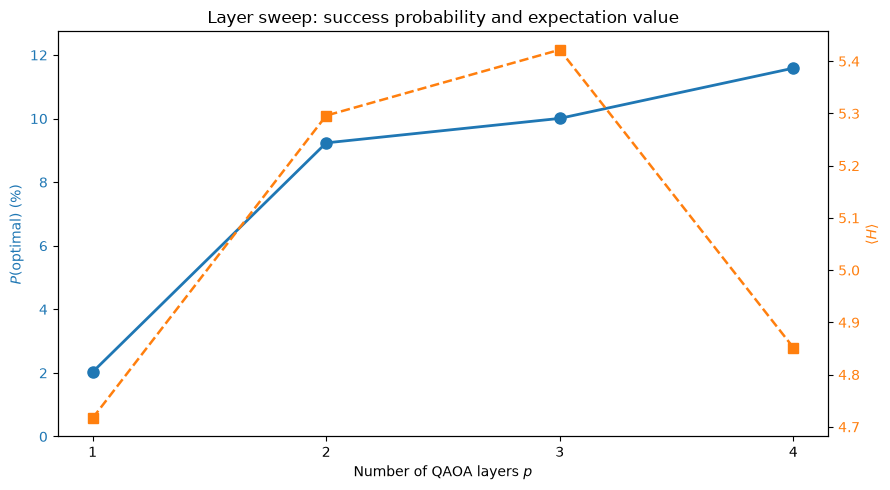

In [23]:
# Best success probability and energy for each number of layers.
layer_values = sorted(best_by_layer)
best_probabilities = [100.0 * best_by_layer[p]["p_optimal"] for p in layer_values]
best_energies = [best_by_layer[p]["energy"] for p in layer_values]

fig, ax_prob = plt.subplots(figsize=(9, 5))
ax_prob.plot(layer_values, best_probabilities, "o-", color="tab:blue", linewidth=2, markersize=8)
ax_prob.set_xlabel("Number of QAOA layers $p$")
ax_prob.set_ylabel(r"$P(\mathrm{optimal})$ (%)", color="tab:blue")
ax_prob.tick_params(axis="y", labelcolor="tab:blue")
ax_prob.set_xticks(layer_values)
ax_prob.set_ylim(0, max(12.0, 1.1 * max(best_probabilities)))

ax_energy = ax_prob.twinx()
ax_energy.plot(layer_values, best_energies, "s--", color="tab:orange", linewidth=1.8, markersize=7)
ax_energy.set_ylabel(r"$\langle H \rangle$", color="tab:orange")
ax_energy.tick_params(axis="y", labelcolor="tab:orange")

ax_prob.set_title("Layer sweep: success probability and expectation value")
fig.tight_layout()
plt.show()

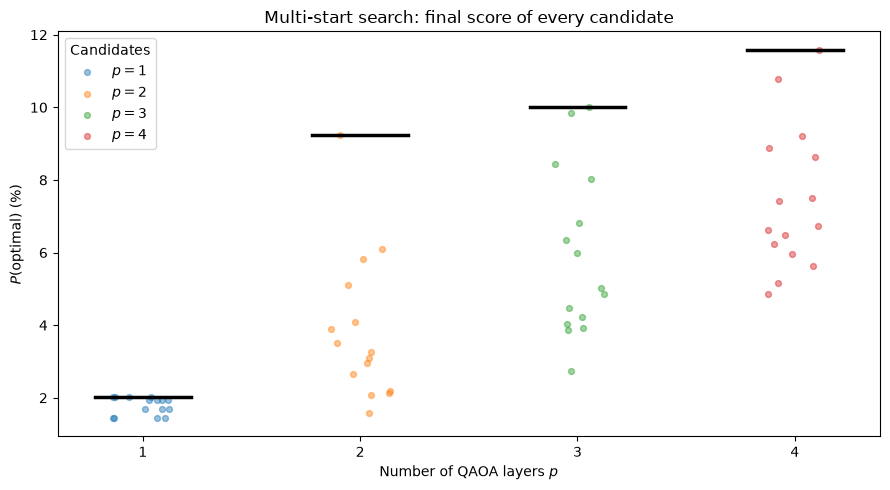

In [24]:
# Every candidate from the multi-start search, grouped by number of layers.
fig, ax = plt.subplots(figsize=(9, 5))
jitter_rng = np.random.default_rng(0)

for p in sorted(best_by_layer):
    values = [
        100.0 * result["p_optimal"]
        for result in search_results
        if result["num_layers"] == p
    ]
    x_positions = p + jitter_rng.uniform(-0.14, 0.14, size=len(values))
    ax.scatter(x_positions, values, s=18, alpha=0.45, label=f"$p={p}$")
    ax.plot(
        [p - 0.22, p + 0.22],
        [100.0 * best_by_layer[p]["p_optimal"]] * 2,
        color="black",
        linewidth=2.5,
    )

ax.set_xlabel("Number of QAOA layers $p$")
ax.set_ylabel(r"$P(\mathrm{optimal})$ (%)")
ax.set_title("Multi-start search: final score of every candidate")
ax.set_xticks(sorted(best_by_layer))
ax.legend(title="Candidates")
fig.tight_layout()
plt.show()

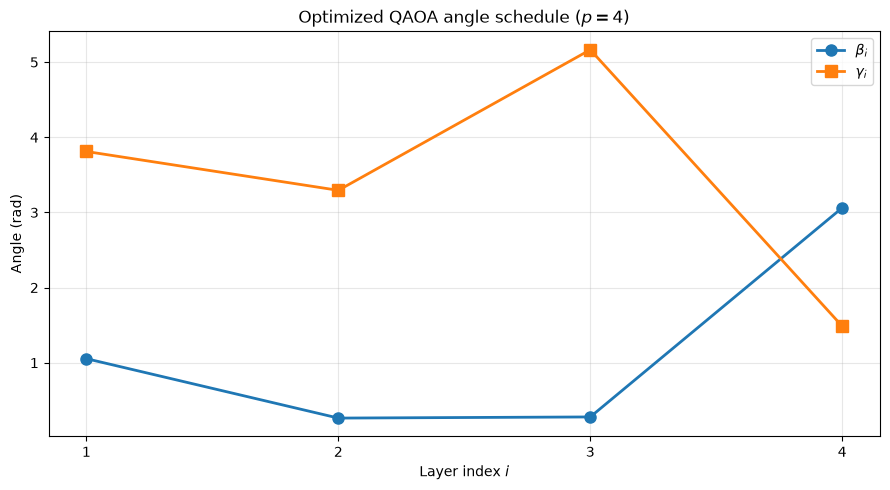

In [25]:
# Optimized angle schedule for the selected circuit.
layer_indices = np.arange(1, num_layers + 1)
betas = opt_params[:num_layers]
gammas = opt_params[num_layers:]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(layer_indices, betas, "o-", linewidth=2, markersize=8, label=r"$\beta_i$")
ax.plot(layer_indices, gammas, "s-", linewidth=2, markersize=8, label=r"$\gamma_i$")
ax.set_xlabel("Layer index $i$")
ax.set_ylabel("Angle (rad)")
ax.set_title(f"Optimized QAOA angle schedule ($p={num_layers}$)")
ax.set_xticks(layer_indices)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

/home/mf/miniconda3/envs/qest-ibm/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/mf/miniconda3/envs/qest-ibm/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/home/mf/miniconda3/envs/qest-ibm/lib/python3.13/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


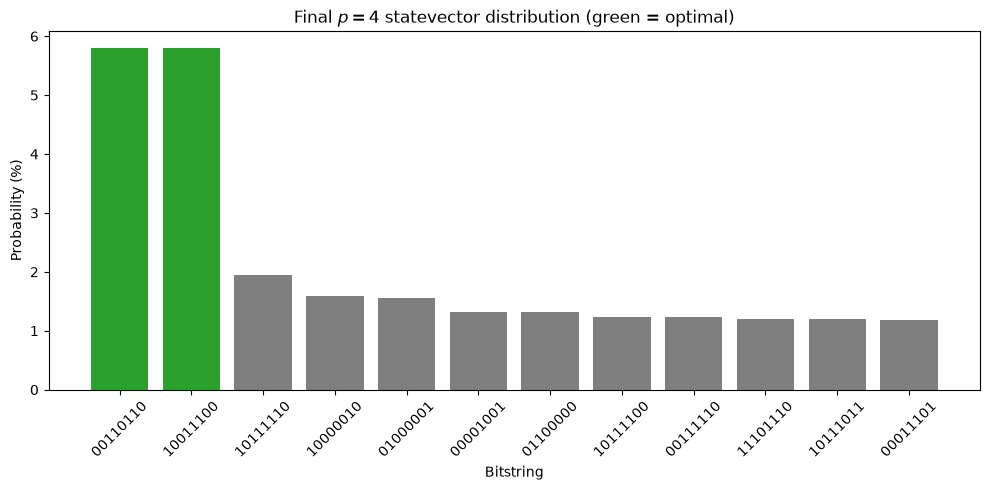

In [26]:
# Exact final distribution, highlighting the optimal routes.
final_state = Statevector(
    QAOAAnsatz(H, reps=num_layers).assign_parameters(opt_params)
)
final_probabilities = final_state.probabilities_dict()
top_outcomes = sorted(final_probabilities.items(), key=lambda item: item[1], reverse=True)[:12]

labels = [bitstring for bitstring, _ in top_outcomes]
values = [100.0 * probability for _, probability in top_outcomes]
colors = ["tab:green" if bitstring in optimal_set else "tab:gray" for bitstring in labels]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(labels, values, color=colors)
ax.set_xlabel("Bitstring")
ax.set_ylabel("Probability (%)")
ax.set_title(f"Final $p={num_layers}$ statevector distribution (green = optimal)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

# Evaluation of the solution

The search above chooses the angles using exact statevector probabilities. This section checks the same circuit with the challenge scoring helper:

- The circuit is sampled with `Sampler` to obtain a probability distribution.
- `utils.compute_score` draws 100,000 shots and returns the percentage of shots that land on an optimal route.
- The exact `P(optimal)` from the statevector is the expected value of that score, so the sampled score should be close to it.

A high score means the QAOA circuit amplifies the optimal patrol routes and suppresses the suboptimal and constraint-violating ones.

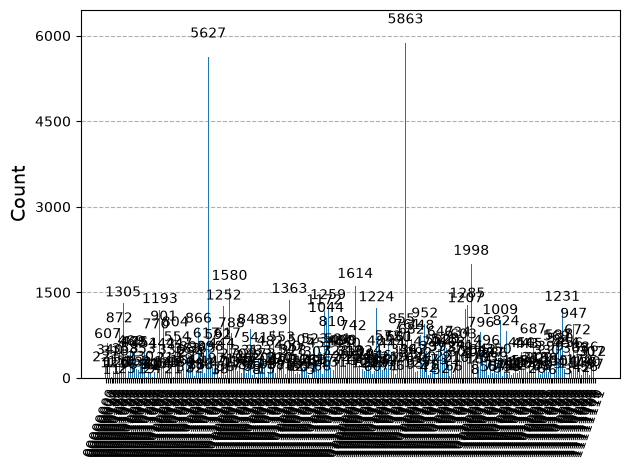

In [27]:
# Instantiate a Sampler to obtain a probability distribution.
sampler = Sampler(mode=backend)
sampler.options.default_shots = 100_000

# Compute the probability distribution with the optimal parameters found during optimization.
circuit_qaoa_copy = circuit_qaoa.decompose(reps=2).copy()
circuit_qaoa_copy.measure_all()
circuit_qaoa_copy.draw()
counts = sampler.run([(circuit_qaoa_copy, opt_params)]).result()[0].data.meas.get_counts()

# Display the probability distribution.
plot_histogram(counts)

In [28]:
# Decode the measured bitstrings into patrol routes.
# Qiskit uses the leftmost character for the highest qubit, so the rightmost
# two bits describe step 0 (qubits 0 and 1).
def bits_of(bitstring):
    """Map each qubit to its measured bit (rightmost character is qubit 0)."""
    return {qubit: int(bitstring[-1 - qubit]) for qubit in range(N_QUBITS)}


def route_cost(bitstring):
    """Raw flight time of a measured route, or None if the route is invalid."""
    route = route_of(bitstring)
    if sorted(route) != [0, 1, 2, 3]:
        return None
    return direct_cost(route)


def itinerary(bitstring):
    """Human-readable visiting order for a measured bitstring."""
    route = route_of(bitstring)
    if sorted(route) != [0, 1, 2, 3]:
        return f"invalid route {route} (repeated or missing station)"
    return " -> ".join(f"S{station}" for station in route)


def constrained_energy(bitstring):
    """Normalized energy of the constrained Hamiltonian for a measured bitstring."""
    bits = tuple(bits_of(bitstring)[qubit] for qubit in range(N_QUBITS))
    return energy_from_terms(H_cost, bits) + ALPHA * energy_from_terms(H_penalty, bits)


num_samples = sum(counts.values())
ranked = sorted(counts.items(), key=lambda item: item[1], reverse=True)

print("Most probable quantum outcomes:")
for bitstring, count in ranked[:8]:
    cost = route_cost(bitstring)
    cost_text = "invalid" if cost is None else f"{cost:.0f} min"
    print(
        f"  {bitstring}  probability={100 * count / num_samples:6.2f}%  "
        f"cost={cost_text:9s}  itinerary: {itinerary(bitstring)}"
    )

best_bitstring, best_count = ranked[0]
print(f"\nQuantum solution : {best_bitstring}  ({100 * best_count / num_samples:.2f}% of shots)")
print(f"  itinerary     : {itinerary(best_bitstring)}")
print(f"  cost          : {route_cost(best_bitstring)} min  (exact minimum: {direct_cost(route_of(binary_sols[0])):.0f} min)")
print(f"  <H>           : {constrained_energy(best_bitstring):.4f}  (exact minimum: {minimum_cost:.4f})")

expected_cost = sum(
    count / num_samples * constrained_energy(bitstring)
    for bitstring, count in counts.items()
)
print(f"  expected <H>  : {expected_cost:.4f}  (exact minimum: {minimum_cost:.4f})")

Most probable quantum outcomes:
  10011100  probability=  5.86%  cost=20 min     itinerary: S0 -> S3 -> S2 -> S1
  00110110  probability=  5.63%  cost=20 min     itinerary: S1 -> S2 -> S3 -> S0
  10111110  probability=  2.00%  cost=invalid    itinerary: invalid route (1, 3, 3, 1) (repeated or missing station)
  10000010  probability=  1.61%  cost=invalid    itinerary: invalid route (1, 0, 0, 1) (repeated or missing station)
  01000001  probability=  1.58%  cost=invalid    itinerary: invalid route (2, 0, 0, 2) (repeated or missing station)
  01100000  probability=  1.36%  cost=invalid    itinerary: invalid route (0, 0, 1, 2) (repeated or missing station)
  00001001  probability=  1.30%  cost=invalid    itinerary: invalid route (2, 1, 0, 0) (repeated or missing station)
  10111100  probability=  1.28%  cost=invalid    itinerary: invalid route (0, 3, 3, 1) (repeated or missing station)

Quantum solution : 10011100  (5.86% of shots)
  itinerary     : S0 -> S3 -> S2 -> S1
  cost          : 

In [29]:
# Evaluate the optimized parameters with the scoring helpers from utils.py
print("Exact minimum cost :", minimum_cost)
print("Exact optimal solutions :", binary_sols)

# Sampled score and expectation value for the QAOA parameters found above.
qaoa_cost, qaoa_score = utils.compute_score(
    params=opt_params, num_layers=num_layers, hamiltonian=H
)
print(f"QAOA score : {qaoa_score:.2f}% of shots on an optimal route")
print(f"QAOA expected cost : {qaoa_cost:.4f} (exact minimum: {minimum_cost:.4f})")
print(f"QAOA optimal bitstring: {best_bitstring}")

Exact minimum cost : 0.9999999999999996
Exact optimal solutions : ['00110110', '10011100']


RuntimeError: generator raised StopIteration

# Save your results

Finally, don't forget to save your results using the `save_res` method available in `utils.py`.

The code below writes `coop_problem_4.npz`. Replace `coop` with your team name if needed. You can check the content of your `.npz` file using the `read_res` method also available in `utils.py`.

In [30]:
utils.save_res(filename="coop_problem_4.npz", params=opt_params, num_layers=num_layers, hamiltonian=H)

# Running the final circuit on an IBM Quantum QPU

The search above uses exact statevector simulation to choose the angles. This final section submits the selected QAOA circuit to a real IBM Quantum backend so the hardware result can be compared with the ideal simulation.

The QPU run uses the least-busy operational backend with at least eight qubits and a modest number of shots (4096). The circuit is transpiled to the backend's native gates and connectivity before submission.

Hardware noise and the transpiled circuit depth usually make the QPU score lower than the exact statevector score. The key check is whether the most probable hardware outcomes are still the optimal routes and whether they satisfy the route constraint.

The cell below is guarded by `RUN_ON_QPU`; set it to `True` to submit a hardware job. It is disabled by default so the notebook can be re-run without spending QPU time.

In [ ]:
RUN_ON_QPU = False

if RUN_ON_QPU:
    from qiskit_ibm_runtime import QiskitRuntimeService

    # Connect to IBM Quantum and choose a real (non-simulator) backend.
    service = QiskitRuntimeService()
    qpu = service.least_busy(operational=True, simulator=False, min_num_qubits=H.num_qubits)
    print(f"QPU backend   : {qpu.name} ({qpu.num_qubits} qubits)")
    print(f"Pending jobs  : {qpu.status().pending_jobs}")

    # Bind the selected angles, measure, and transpile for the QPU.
    qpu_circuit = QAOAAnsatz(H, reps=num_layers).assign_parameters(opt_params)
    qpu_circuit.measure_all()
    pm_qpu = generate_preset_pass_manager(backend=qpu, optimization_level=2)
    isa_qpu_circuit = pm_qpu.run(qpu_circuit)
    print(f"Transpiled depth: {isa_qpu_circuit.depth()}")

    # Submit the hardware job.
    qpu_sampler = Sampler(mode=qpu)
    qpu_sampler.options.default_shots = 4096
    qpu_job = qpu_sampler.run([(isa_qpu_circuit,)])
    print(f"QPU job id    : {qpu_job.job_id()}")
    qpu_counts = qpu_job.result()[0].data.meas.get_counts()

    # Score the hardware result with the same criterion as the grader.
    qpu_shots = sum(qpu_counts.values())
    qpu_optimal_counts = sum(
        count for bitstring, count in qpu_counts.items() if bitstring in optimal_set
    )
    qpu_score = 100.0 * qpu_optimal_counts / qpu_shots

    print(f"QPU shots     : {qpu_shots}")
    print(f"QPU score     : {qpu_score:.2f}% of shots on an optimal route")
    print("QPU top outcomes:")
    for bitstring, count in sorted(qpu_counts.items(), key=lambda item: item[1], reverse=True)[:5]:
        print(
            f"  {bitstring}  probability={100.0 * count / qpu_shots:6.2f}%  "
            f"itinerary={itinerary(bitstring)}"
        )

    plot_histogram(qpu_counts)
else:
    print("QPU run skipped (set RUN_ON_QPU = True to submit a hardware job).")

# Takeaways